# Step 5 · 城市交通事件语义图谱构建与编码

本 Notebook 展示因果历史基线异常检测、带证据和生成方式的 MultiDiGraph、关系感知语义编码器，以及统一 Case 的 Figure 11–16。速度异常只解释为拥堵样异常，不作为事故或原因标签。治理规则全部标注为 illustrative。

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'pyproject.toml').exists())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from urban_joint_encoder.visualization.semantic_plots import load_graph
from urban_joint_encoder.visualization import make_step5_figures
event_report=json.loads((ROOT/'outputs/metrics/event_detection.json').read_text(encoding='utf-8'))
audit=json.loads((ROOT/'outputs/metrics/semantic_graph_audit.json').read_text(encoding='utf-8'))
metadata=json.loads((ROOT/'outputs/embeddings/E_se_metadata.json').read_text(encoding='utf-8'))
graph=load_graph(ROOT/'outputs/graphs/semantic_graph.json')
print('Project root:',ROOT)

Project root: /Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder


## 1. Schema 与证据等级

每个节点和关系都带唯一 ID、类型、属性、数据来源、证据与 `generation_method`。四种生成方式严格区分为 observed、derived、inferred 和 illustrative。

In [2]:
display(pd.DataFrame(audit['schema']['node_types']).T)
display(pd.DataFrame(audit['schema']['relationship_types']).T)
display(pd.Series(audit['graph']['node_counts_by_type'],name='nodes').to_frame())
display(pd.Series(audit['graph']['edge_counts_by_type'],name='edges').to_frame())

,unique_id,properties,source,generation_method
SpatialGrid,grid:{matrix_column_index},"[node_index, poi_counts]",headerless traffic/POI matrices,observed
POICategory,poi_category:{index},[category_name],author POI query categories,observed
CongestionEvent,event:grid_{node}:rows_{start}_{end},"[row range, robust anomaly evidence]",traffic speed matrix,derived
GovernanceRule,rule:{name},"[condition, suggested_action]",project demonstration only,illustrative


,source,generation_method,evidence
HAS_POI,POI count files,observed,positive per-grid category count
OCCURS_AT,event detector,derived,event node_index
ADJACENT_TO,adj_matrix.csv,observed,binary matrix entry
TEMPORALLY_PRECEDES,event row ranges,derived,ordered non-identical starts
POTENTIALLY_PROPAGATES_TO,adjacency + event timing + anomaly strength,inferred,candidate association; explicitly non-causal
TRIGGERS_RULE,demonstration threshold,illustrative,rule condition evaluated on derived event


,nodes
SpatialGrid,265
POICategory,7
CongestionEvent,3
GovernanceRule,2


,edges
HAS_POI,1418
OCCURS_AT,3
ADJACENT_TO,624
TEMPORALLY_PRECEDES,2
POTENTIALLY_PROPAGATES_TO,1
TRIGGERS_RULE,2


## 2. 无未来泄漏的事件检测

对测试段每个节点和当前行，只使用此前最多 21 天、相同日内槽位 ±1 个槽位的历史样本。当前速度同时低于历史 Q10、稳健 Z 分数至少 2，并较历史中位数低至少 2 个速度单位，才记为异常点；连续至少 2 步才合并为事件。分母采用 `1.4826 × MAD + 0.25`，避免 MAD 极小时分数爆炸。

In [3]:
case=event_report['selected_case']; selected=case['selected_event']
display(pd.Series(selected,name='selected_case_event').to_frame())
display(Markdown(f"测试段共检测到 **{event_report['detected_event_count']}** 个持续事件片段。统一 Case 使用 row **{case['case_row_index']}**；主事件位于矩阵节点 **{selected['node_index']}**，范围 **{selected['start_row_index']}–{selected['end_row_index']}**。"))

,selected_case_event
event_id,event:grid_146:rows_7345_7349
node_index,146
start_row_index,7345
end_row_index,7349
duration_steps,5
peak_row_index,7346
peak_robust_z,5.884821
mean_robust_z,5.195119
mean_observed_speed,7.554198
peak_observed_speed,6.889542


测试段共检测到 **791** 个持续事件片段。统一 Case 使用 row **7347**；主事件位于矩阵节点 **146**，范围 **7345–7349**。

## 3. 图谱审计

全图保留全部 265 个网格及其真实 POI、空间邻接，同时只把统一 Case 时刻活跃的事件纳入 Case 图。候选传播要求：真实相邻网格、下游事件晚 1–3 步开始，并记录两端异常强度；它只是候选关联，不是因果结论。

In [4]:
print('MultiDiGraph:',isinstance(graph,nx.MultiDiGraph),'nodes:',graph.number_of_nodes(),'edges:',graph.number_of_edges())
candidate=[(u,v,d) for u,v,k,d in graph.edges(keys=True,data=True) if d['type']=='POTENTIALLY_PROPAGATES_TO']
display(pd.DataFrame([{'source':u,'target':v,**d} for u,v,d in candidate]))
assert all(d['generation_method']=='inferred' and d['causal_claim']==False for _,_,d in candidate)

MultiDiGraph: True nodes: 277 edges: 2050


,source,target,id,type,lag_steps,confidence,causal_claim,data_source,evidence,generation_method
0,event:grid_146:rows_7345_7349,event:grid_147:rows_7347_7348,candidate:event:grid_146:rows_7345_7349:event:...,POTENTIALLY_PROPAGATES_TO,2,0.776573,False,adjacency + event detector,adjacent grids; downstream event starts 2 step...,inferred


## 4. 关系感知语义编码器

两层轻量关系消息传递网络为 6 种关系分别学习权重。训练目标是关系边重建 BCE 与节点属性重建 MSE 的组合；正负边按固定随机种子构造，最佳权重由验证边 AUC 选择。

In [5]:
training=audit['semantic_encoder_training']
display(pd.DataFrame(training['history']).tail())
display(pd.Series({k:v for k,v in training.items() if k!='history'},name='semantic_encoder').to_frame())
E_se=np.load(ROOT/'outputs/embeddings/E_se.npy')
E_st_meta=json.loads((ROOT/'outputs/embeddings/E_st_metadata.json').read_text(encoding='utf-8'))
print('E_se:',E_se.shape,E_se.dtype,'E_st aligned row:',E_st_meta['target_row_index'])
assert E_se.shape==(277,32) and E_st_meta['target_row_index']==case['case_row_index']==7347

,epoch,training_loss,edge_reconstruction_loss,attribute_reconstruction_loss,validation_edge_bce,validation_edge_auc
61,62,0.240602,0.236631,0.015882,0.250871,0.950101
62,63,0.240330,0.236416,0.015655,0.250698,0.950297
63,64,0.240037,0.236173,0.015457,0.250625,0.950654
64,65,0.239830,0.236011,0.015276,0.250690,0.950785
65,66,0.239565,0.235799,0.015067,0.250929,0.950642


,semantic_encoder
objective,relation-aware edge reconstruction (BCE) + nod...
seed,42
epochs_completed,66
best_epoch,41
best_validation_edge_auc,0.951856
train_edge_count,1640
validation_edge_count,410
negative_sampling,equal number of fixed-seed corrupt non-edges p...
parameter_count,12050


E_se: (277, 32) float32 E_st aligned row: 7347


## 5. Figure 11–16

Schema 和消息传播图是明确标注的程序化示意；时间线来自真实速度；事件链来自实际检测与邻接证据；知识图谱为固定种子的拓扑布局而非地图；嵌入图来自训练后的最佳模型。

findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


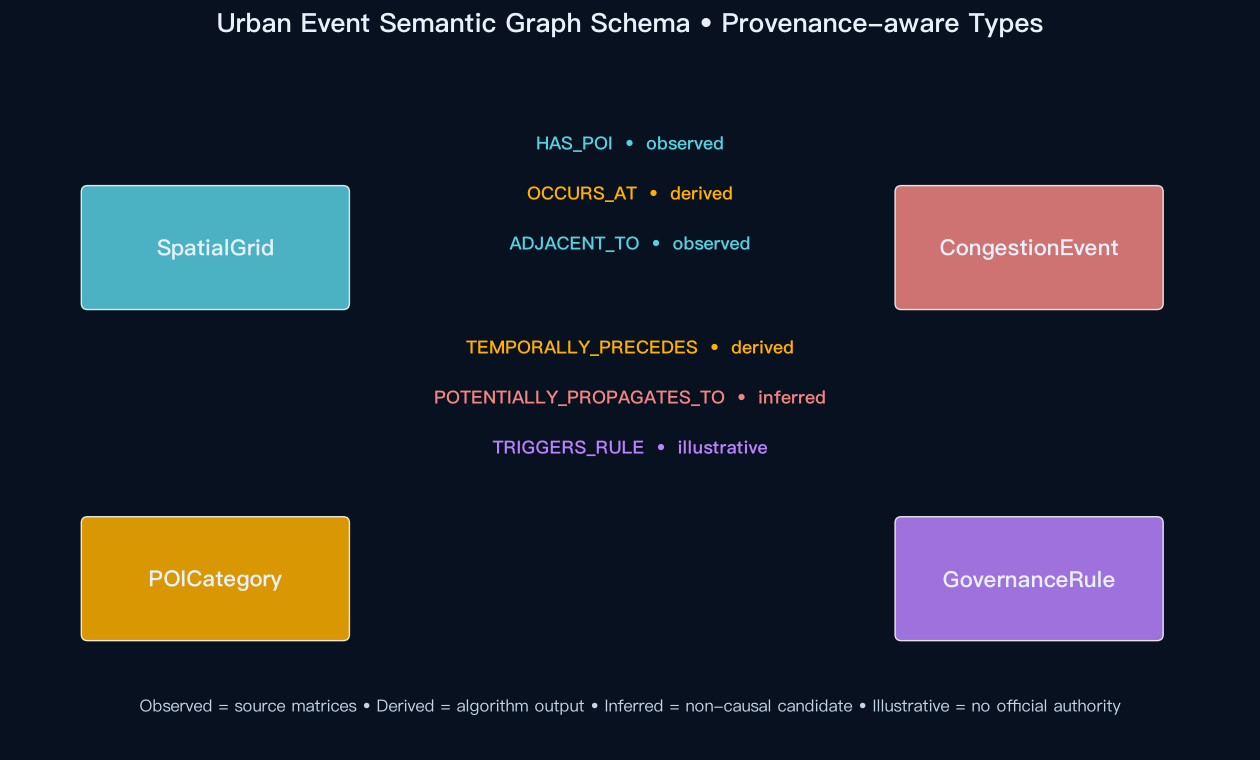

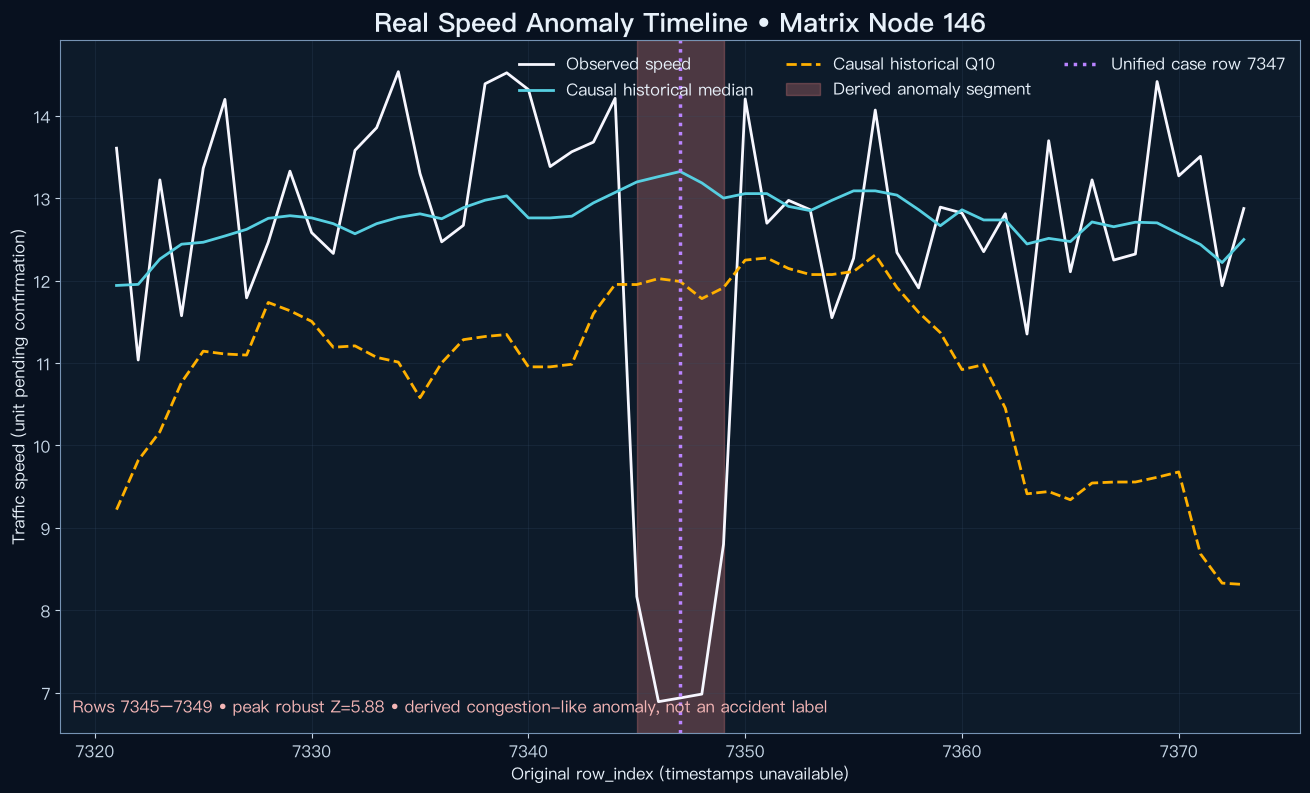

findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


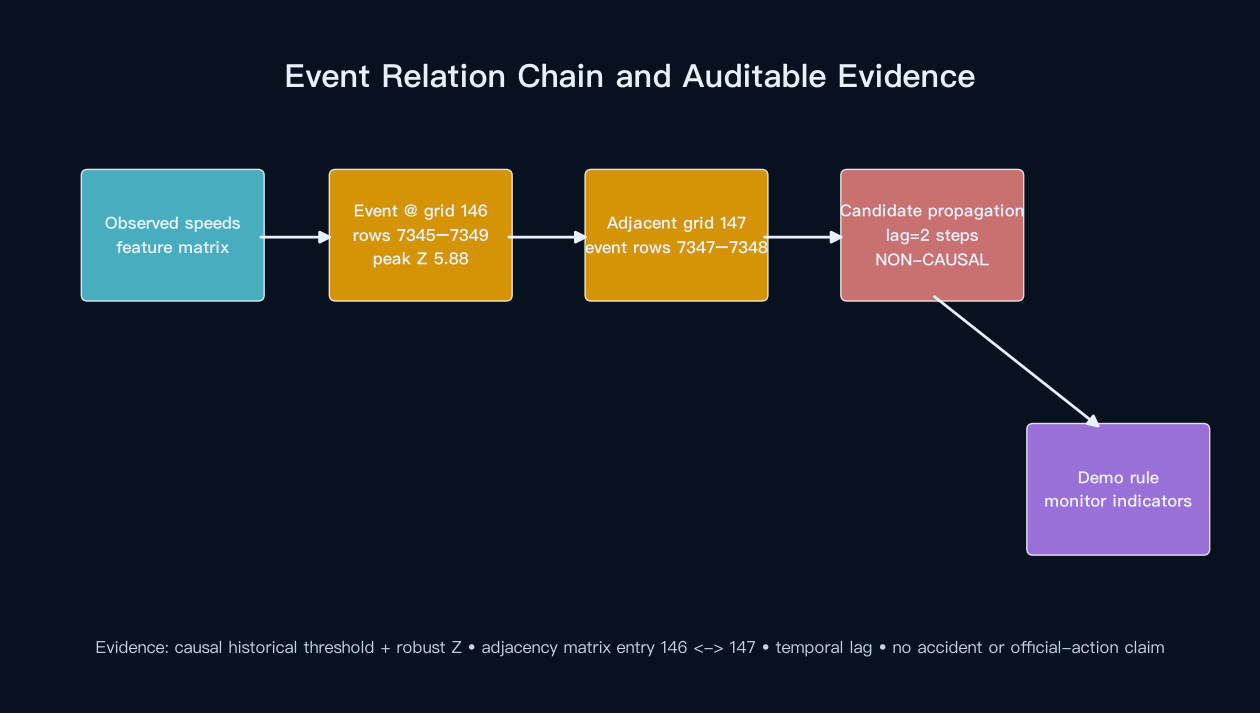

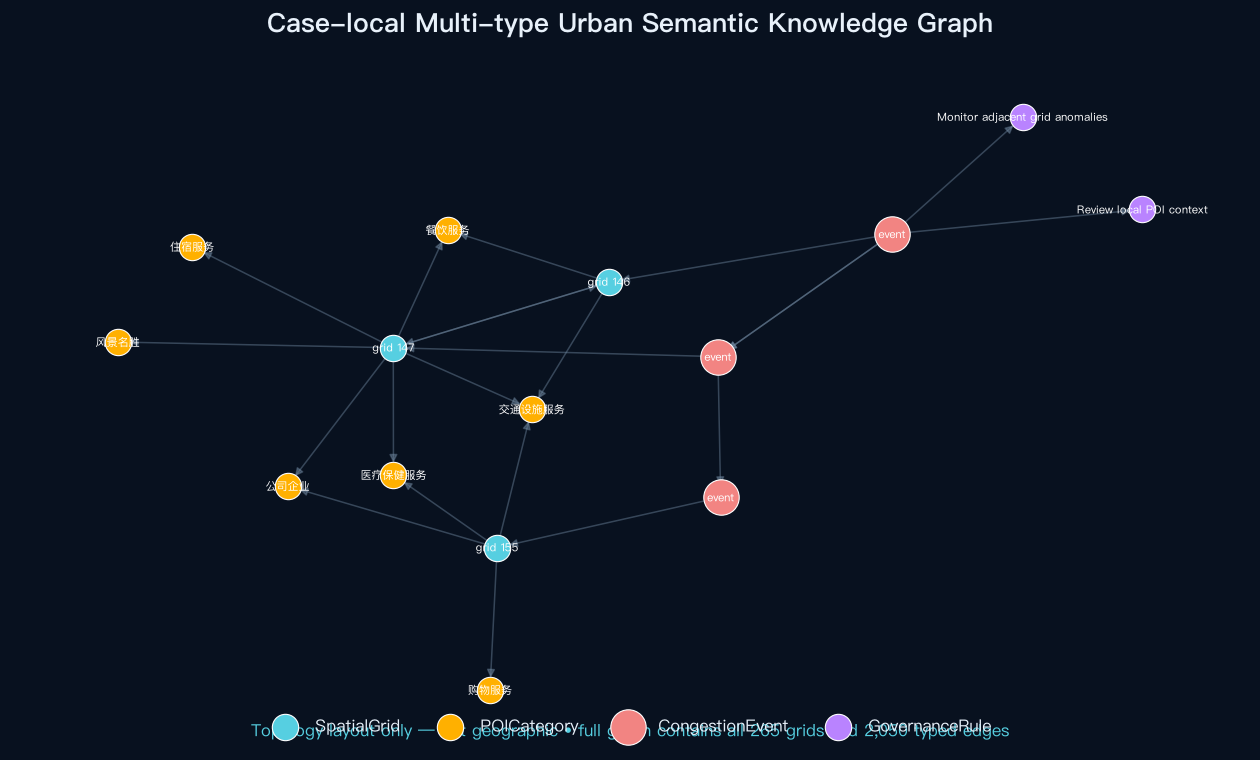

findfont: Failed to find font weight bold for PingFang SC, now using 600.


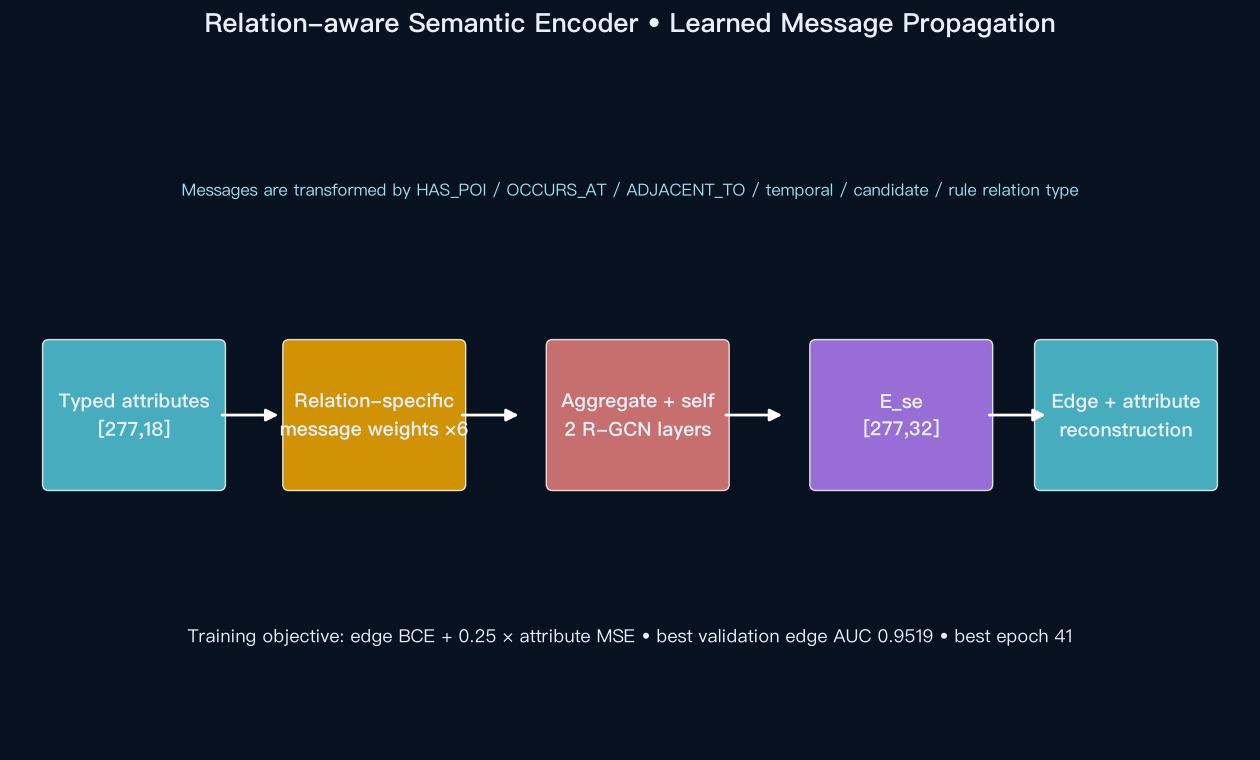

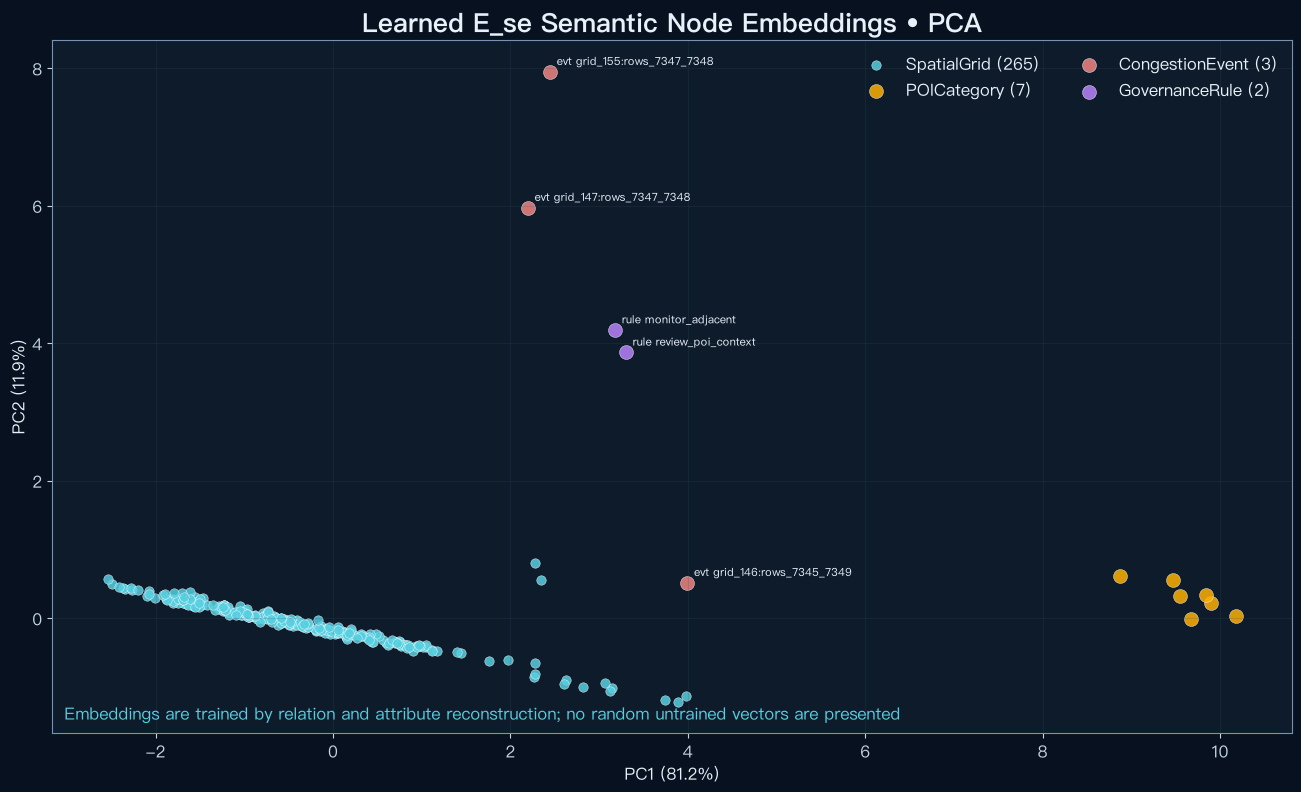

,PNG,SVG
figure_11,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_12,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_13,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_14,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_15,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_16,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...


In [6]:
figure_outputs=make_step5_figures(ROOT)
display(pd.DataFrame({k:v for k,v in figure_outputs.items()},index=['PNG','SVG']).T)

## 6. 限制与下一阶段接口

`E_se.npy` 为所有类型语义节点的 `[M,32]` 表示，节点顺序必须通过 `E_se_metadata.json` 映射，不应强行裁剪成 265 个网格。当前没有时间戳、地理 FID 或坐标；异常不能说明事故或原因；传播仅是候选关联；规则不是官方政策或真实处置记录。本阶段不执行 Cross-Attention 或联合融合。